# Del1 

## Introduktion och syfte

Syftet med analysen är att bestiva ett hälsodataset och undreköka påstånde att rökare har högre genomsnittligt blodryck än icke-rökare.  

Analysen omfattar beskrivande statistik, diagram, simulering av sjukdomförekomst, 95% konfidensintervall (normalapproximation och boostrap), ett ensidigt Welchs t-test och en simulering av statistisk power. 

Data kommer från datasatet health_study_dataset.csv. Simulerade data advänds för att illustrera hur statistiska metoder funkar, inte som oberoende bevis för samband i population.

### 1.1. Import av bibliotek

In [1]:
import sys
from pathlib import Path

current = Path.cwd()

if (current / "src").exists():
    project_root = current
elif (current.parent / "src").exists():
    project_root = current.parent
else:
    raise FileNotFoundError("src hittades inte")

sys.path.insert(0, str(project_root))

In [2]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


from src.analyzer import HealthAnalyzer
import src.viz
import importlib

importlib.reload(src.viz)



<module 'src.viz' from 'c:\\Users\\kataz\\Desktop\\skola\\health_analysis\\src\\viz.py'>

### 1.2. Datainläsning

In [3]:

df = pd.read_csv(project_root / "data" / "health_study_dataset.csv")

analyzer = HealthAnalyzer(df)


### 1.3. Grundläggande beräkningar för blodtryck

Här beräknas medelvärde, standardavvikels och standartfel för systoliska blotrycket. Saknades värden tas bort före beräkningena.

In [4]:
bp_stats = analyzer.summary("systolic_bp")
bp_stats

{'count': 800,
 'mean': np.float64(149.178625),
 'median': np.float64(149.4),
 'max': np.float64(185.9),
 'min': np.float64(106.8),
 'std': np.float64(12.793360316766597),
 'se': np.float64(0.4523135917074269)}

### 1.4. Konstanter

Konstanterna samlas här för att göra analysen tydlig och reproducerbar.  
`RANDOM_SEED` används för att simuleringarna ska kunna upprepas.  
 Signifikansnivån sätts i förväg till `ALPHA = 0.05`.  
 Antalet power-simuleringar är 10 000 per scenario, vilket minskar slumpvariation i den simulerade andelen signifikanta test.

In [5]:
from src.config import (
    RANDOM_SEED,
    ALPHA,
    SEX_COLUMN,
    SMOKER_COLUMN,
    SIM_GROUP_SIZE,
    N_BOOTSTRAP,
    BOOTSTRAP_START,
    BOOTSTRAP_STEP,
    N_POWER_SIM,
    POWER_SAMPLE_SIZE,
    )

### 1.5. Färgpalett och figurstil för visualisering



In [6]:
from src.styles import COLORS, SMOKING_COLORS, SEX_COLORS


### 1.6. Inställningar för diagrammers utseende

Funktion `setup_plot_style()` används för att säkerställa en enhetlig och konsekvent utformning av diagrammen.

In [7]:
from src.styles import setup_plot_style

setup_plot_style()

## 2. Översikt över datasetet

### 2.1. Datasetets struktur och datatyper

In [8]:
print("Databesets första tre råder:")
display(df.head(3))

print("Databesets sista tre råder:")
display(df.tail(3))

print(f"\nDatasetet  --  -  Antal rader: {df.shape[0]}  --  Antal kolumner: {df.shape[1]}")
print(f"\n{"Kolumnamn":<20} Datatype:")
for column in df.columns:
    print(f" - {column:<15} : {df[column].dtype}")

Databesets första tre råder:


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0


Databesets sista tre råder:


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
797,798,60,F,175.0,49.7,146.5,5.57,No,0
798,799,50,F,172.6,55.3,155.0,3.58,No,0
799,800,50,M,189.2,79.4,139.7,5.62,No,0



Datasetet  --  -  Antal rader: 800  --  Antal kolumner: 9

Kolumnamn            Datatype:
 - id              : int64
 - age             : int64
 - sex             : str
 - height          : float64
 - weight          : float64
 - systolic_bp     : float64
 - cholesterol     : float64
 - smoker          : str
 - disease         : int64


### 2.2. Datavalidering 

Här kontrolleras Id_värdena är unika och kolumnerna för kön, rökstatus och sjukdom innehäller förväntade värde.

"Korrekt" betyder att endast en kontrollerade regeln har uppfyllts, inte att alla datavärden är felfria.

In [9]:
validation_results = analyzer.validate()

display(
    pd.DataFrame(validation_results, index=["Validering"]).replace({True:"Korrekt", False:"Fel"})
)

,id,sex,smoker,disease
Validering,Korrekt,Korrekt,Korrekt,Korrekt


### 2.2.1. Saknade värden i datasetet

Tabellen visar antalet saknade värden i varje kolumn.

In [10]:
missing_values = analyzer.missing_values()

display(missing_values.to_frame(name="Saknade värden").T)

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Saknade värden,0,0,0,0,0,0,0,0,0


Det finns inga saknade värden i databasen.

### 2.2.2. Validering av datatyper

Här kontrolleras datatyper för värderna i varje kolumn innehäller med förväntade datatyper.

"Korrekt" betyder att endast en kontrollerade regeln har uppfyllts, men bekräftar inte i sig att alla numeriska värde är rimliga.

In [11]:
type_results = analyzer.validate_types()

display(
    pd.DataFrame({column: "Korrekt" if valid else "Fel"
                  for column, valid in type_results.items()},
                  index=["Datatyp validering"])
)


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Datatyp validering,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt


Inga saknade värden eller avvikelser från de kontrollerade datatyperna och kategorierna upptäcktes.  
Kontroll av medicinskt rimliga gränsvärden eller mätfel ingår däremot inte här.

## 3. Beskrivande analys för datasetet

### 3.1. Beskrivande statistik för datasetet

In [12]:
columns = [ "age", "height", "weight", "systolic_bp", "cholesterol"]


calculate_columns = pd.DataFrame({
    column: analyzer.summary(column) for column in columns
})
calculate_columns = calculate_columns.loc[["mean", "median", "min", "max"]]

calculate_columns = calculate_columns.rename(index={
    "mean": "Medelvärde", "median":"Median", "min": "Minimun", "max": "Maximum"})

display(calculate_columns.round(2))

,age,height,weight,systolic_bp,cholesterol
Medelvärde,49.43,171.85,73.41,149.18,4.93
Median,50.00,171.35,73.20,149.40,4.97
Minimun,18.00,144.40,33.70,106.80,2.50
Maximum,90.00,200.40,114.40,185.90,7.88


Medelvärdet och medianen ligger nära varandra för alla fem variabler, vilket kan tyda på att fördelningarna är ungefär symmetriska. Detta är dock ingen bevis på symmetri.

### 3.2. Visualisering

Olika diagram visar hur hälsodata är fördelade.

#### 3.2.1 Fördelning av systoliskt blodtryck

Histogramme visar fördelningen av systolisk blodtryck för 800 personar

Mean 149.178625
median 149.4


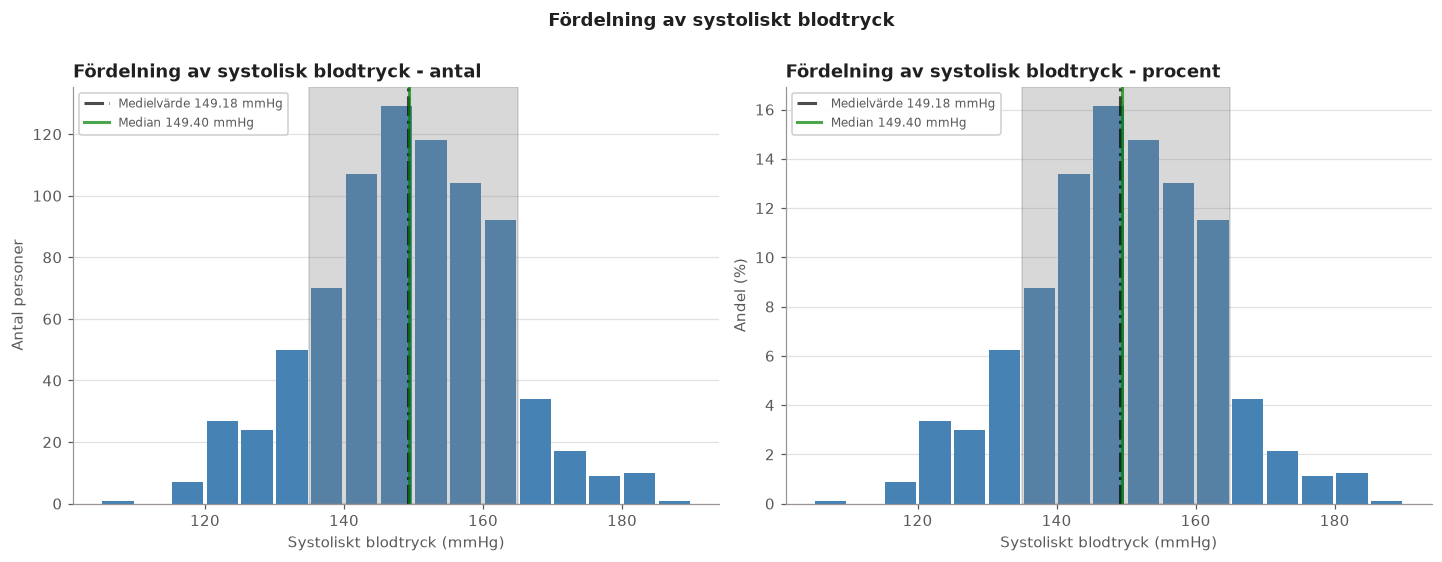

In [13]:
from src.metrics import    calculate_multiple_regression
from src.viz import plot_histogram, plot_boxplot, plot_smoking_status, plot_smoking_by_sex, plot_bootstrap_stability


bp_values = df["systolic_bp"].dropna()

bp_bin_width = 5
bp_bins = np.arange(
    np.floor(bp_values.min() / bp_bin_width) * bp_bin_width,
    np.ceil(bp_values.max() / bp_bin_width) * bp_bin_width + bp_bin_width,
    bp_bin_width,
)
bp_stats = analyzer.summary("systolic_bp")

bp_mean = bp_stats["mean"]
bp_median = bp_stats["median"]
bp_hist_counts, bp_hist_percent, bp_bin_centers = analyzer.histogram("systolic_bp", bp_bins)
print("Mean",bp_mean)
print("median", bp_median)


fig_bp, axes_bp = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
plot_histogram(
    ax=axes_bp[0],
    bin_centers=bp_bin_centers,
    values=bp_hist_counts,
    bin_width=bp_bins[1]- bp_bins[0],
    color="steelblue",
    ylabel="Antal personer",
    title="Fördelning av systolisk blodtryck - antal",
    mean=bp_mean,
    median=bp_median,
)
plot_histogram(
    ax=axes_bp[1],
    bin_centers=bp_bin_centers,
    values=bp_hist_percent,
    bin_width=bp_bins[1]- bp_bins[0],
    color="steelblue",
    ylabel="Andel (%)",
    title="Fördelning av systolisk blodtryck - procent",
    mean=bp_mean,
    median=bp_median,
)


fig_bp.suptitle("Fördelning av systoliskt blodtryck\n", fontweight="bold")
plt.show()


Av 800 personer har 623 (77,88 %) systoliskt blodtryck mellan 135 och 165 mmHg. Medelvärdet är cirka 149,18 mmHg och ligger nära medianen 149,40 mmHg. Histogrammet ser ungefär symmetriskt ut, men likheten mellan medelvärde och median bevisar inte symmetri.  
  
Intervallet 135–165 mmHg används här **endast** för att beskriva fördelningen.


#### 3.2.2 Viktfördelning efter kön

Lådagram jämför viktfödelningen mellan kvinnor och män.  
Diagrammet visar medianen, kvartilerna och spridningen av vikten och avvikande värde.

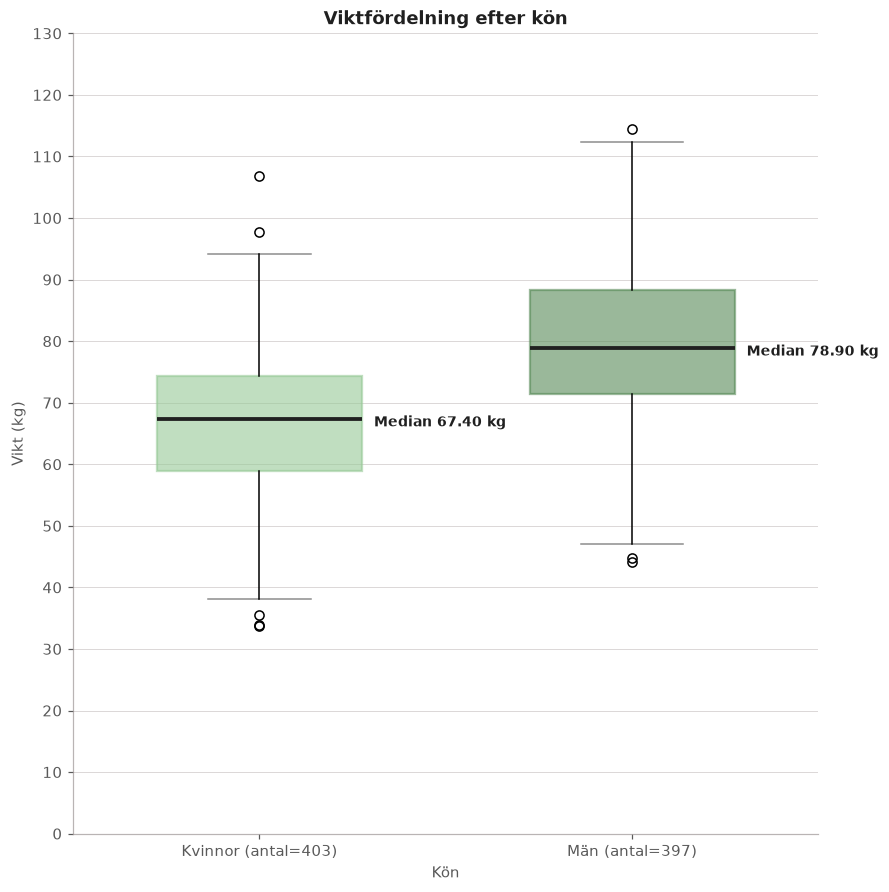

In [14]:
from src.styles import style_axis

weight_groups, median_weight_by_sex = analyzer.weight_by_sex(SEX_COLUMN)

weight_labels = [
    f"{label} (antal={len(values)})"
    for label, values in zip(["Kvinnor", "Män"], weight_groups)
]
fig_weght, ax_weight = plt.subplots(
    figsize=(8, 8),
    layout="constrained"
)

plot_boxplot(
    ax=ax_weight,
    weight_groups=weight_groups,
    weight_labels=weight_labels,
    sex_column=SEX_COLUMN,
    sex_colors=SEX_COLORS,
    colors=COLORS,

    median_weight_by_sex=median_weight_by_sex,
)

style_axis(ax_weight)

plt.show()


Män i datasetet har en högre medianvikt än kvinnor. Skillnaden mellan medianerna är 11,50kg.  
Båda grupperna har några avvikande värden.

#### 3.2.3. Rökvanor i hela databaset

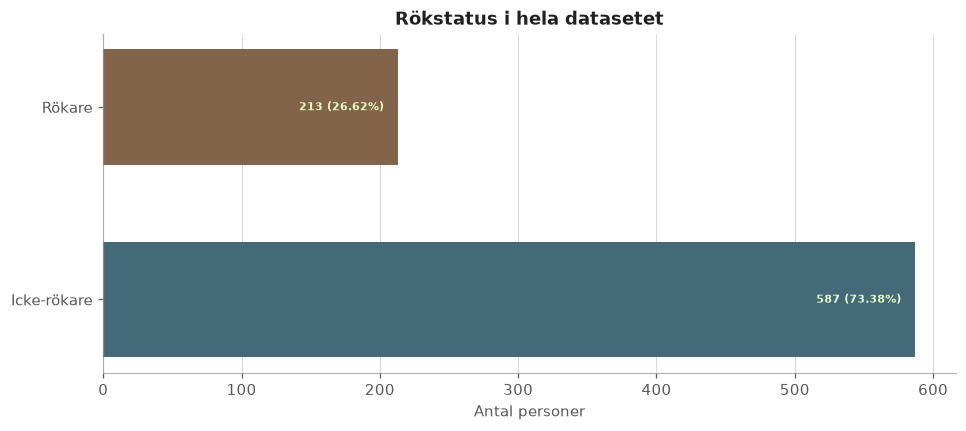

In [15]:
smoking_counts, smoking_perc, smoking_all_counts = analyzer.smoking_stats( SEX_COLUMN, SMOKER_COLUMN, )

fig_smoking, ax_smoking = plt.subplots(figsize=(10, 4))

plot_smoking_status(ax=ax_smoking,
                    smoking_all_counts=smoking_all_counts,
                    smoker_column=SMOKER_COLUMN,
                    smoking_colors=SMOKING_COLORS,
                    colors=COLORS,
                    )

style_axis(ax_smoking, grid_axis="x")

plt.show()

Av totalt 800 personer är 587(73,38%) icke-rökare och 213(26,62%) rökare. Rökare utgör minoritet i databaset.

#### 3.2.4. Rökstatus efter kön

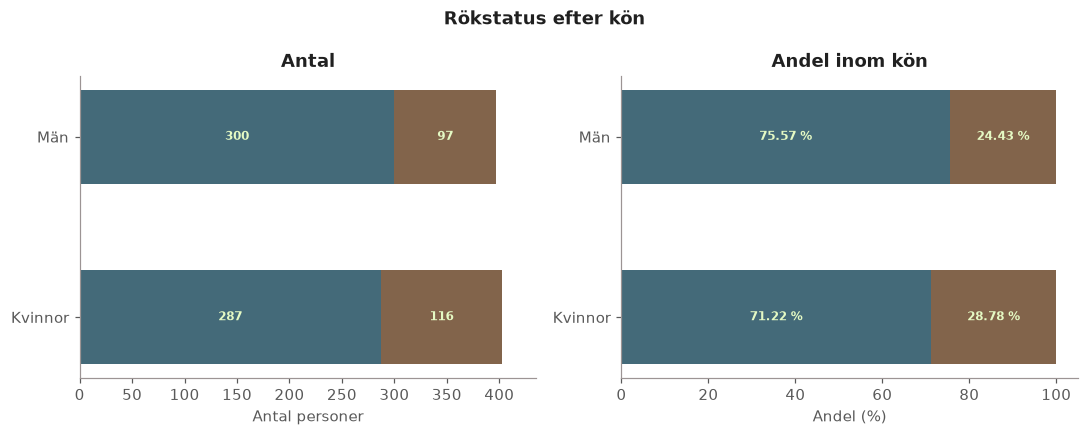

In [16]:
fig_smoking_sex, axes_smoking_sex = plt.subplots(1, 2, figsize=(10, 4), layout="tight")

plot_smoking_by_sex(
    axes=axes_smoking_sex,
    smoking_counts=smoking_counts,
    smoking_perc=smoking_perc,
    sex_column=SEX_COLUMN,
    smoker_column=SMOKER_COLUMN,
    smoking_colors=SMOKING_COLORS,
    colors=COLORS,
)

fig_smoking_sex.suptitle("Rökstatus efter kön", fontweight="bold")
plt.show()

Andelen rökare och icke-rökare är relativt lika bland kvinnor och män. Åndelen rökare i datasetet är något högre bland kvinnor(28,78%) än bland män(24,43%).  
Diagrammet visar mönster, doch bevisar inte orsakssamband mellan kön och rökstatus.

## 4. Simulering kopplad till caset

### 4.1 Andelen personer i datasetet som har sjukdom

 I analysen antar vi att:
 disease = 0 betyder att personen har inte sjukdom och att disease = 1 betyder att personen har sjukdomen.

In [17]:
disease_rate = analyzer.disease_rate()

print(f"Andel personer med sjukdom:{disease_rate:.4%}")

Andel personer med sjukdom:5.8750%


### 4.2 Ny grupp med 1 000 slumpade personer 

Ny grupp har 1000 simulerade personer med samma sannolikhet för sjukdom som i det ursprungliga databaset(5,875%) och däeför har ingen oberoende kontroll av sjukdomsförekomsten i population.  
Att resultatet ska bli reproducerbar används fast seed.

In [18]:
simulated_yes_group = analyzer.simulate_disease(SIM_GROUP_SIZE, RANDOM_SEED)
print(f"simulerad andel med sjukdom: {simulated_yes_group:.2%}")


simulerad andel med sjukdom: 5.40%


I ny grupp är 54 personer med sjukdom.

### 4.3. Jämförelse

In [19]:
difference = analyzer.disease_difference(simulated_yes_group)

print(f" Andel personer med sjukdom i datasetet:  {disease_rate:.4%}")
print(f" Simulerad andel med sjukdom:             {simulated_yes_group:.4%}")
print(f" Skillnad:                               {difference:.4%}")

 Andel personer med sjukdom i datasetet:  5.8750%
 Simulerad andel med sjukdom:             5.4000%
 Skillnad:                               -0.4750%


Andelen personer med sjukdom är 5,875% i det utsprungliga datasetet och 5,400% i den simmulerade gruppen. Skillnaden är resultat av slumpmässig variation i simuleringen.

## 5. Konfidensintervall - normalapproximation

### 5.1. Värdena

Värdena beräknades i avsnitt 1.

In [20]:
bp_satats = analyzer.summary("systolic_bp")
                             
results = pd.DataFrame({
    "Statistik": ["Medelvärde:",
                   "Standardavvikelse:",
                   "Antal observationer:",
                   "Standardfel:"
                       ],
    "Värde": [
        f"{bp_stats["mean"]:.4f} mmHg",
        f"{bp_stats["std"]:.4f} mmHg",
        str(bp_stats["count"]),
        f"{bp_stats["se"]:.4f} mmHg"
                       ]
})

display(results.style.hide(axis="index"))

Statistik,Värde
Medelvärde:,149.1786 mmHg
Standardavvikelse:,12.7934 mmHg
Antal observationer:,800
Standardfel:,0.4523 mmHg


### 5.2 Konfidensintervall - felmarginal, gränser

Ett 95 % konfidensintervall adväns att ge rimlig balans mellan precisin och säkerhet. Det betyder att om nytt intervall räknas för samma undersökning om och om, skulle ungefär 95% av intervallen innehålla det verkliga medelvärde för hela population. Verkliga medelvärde för hela population vet vi inte. Räkning utgåt från att datasetet är representativt för population.  

SE är standartfel  
s är standartavvikelse  
n är antal observation(datasetet har 800)  
$ \bar{x} $ är medelvärde(i datasetet är 149,18 mmHg )

$
KI_{95\%} = \bar{x} \pm 1,96 \cdot SE  
$  
$
SE = \frac{s}{\sqrt{n}}
$

In [21]:
normal_margin, normal_ci = analyzer.normal_ci("systolic_bp", ALPHA)

print(f"Felmarginal: {normal_margin:.4f} mmHg")
print(f"normalapproximations gränser: {normal_ci[0]:.4f} mmHg och {normal_ci[1]:.4f} mmHg")

Felmarginal: 0.8865 mmHg
normalapproximations gränser: 148.2921 mmHg och 150.0651 mmHg


Resultatet visar, doch inte garanterar att det genomsnittliga blodtrycket i hela population uppskattes ungefär mellan 148,2921 och 150,0651 mmHg, baserad på data i datsetet.  
Felmarginal visar hur osäkert vårt medetvärde är som uppskattning av hela populations medevärde. I vårt fall går 0,8865 mmHg (felmarginal) under och över medelvärdet(149,18 mmHg).

## 6. Konfidensintervall - bootstrap

I den här delen görs många slupmässiga urval från ursprungliga dataset. Varje urval innehåller 800 värden, samma värde kan väljas flera gånger.  
Ett fast seed advänds för att resultat ska uppraperas.  
Medelvärde räknas ut för varje urval och resultat är att konfidensintervall kan uppskattas.

Bootstrap kräver inte exakt normelfördelade blodtryckvärdena, Storleken på observation är tillräklig stor, men resultat beror på representativ urval och metods begränsningar.

In [22]:
bootstrap_batch_size = 2000
bootstrap_means = analyzer.bootstrap_means("systolic_bp", N_BOOTSTRAP, bootstrap_batch_size, RANDOM_SEED)



### 6.1 Bootstrapintervallets gränser

In [23]:
bootstrap_ci =  analyzer.bootstrap_ci(bootstrap_means, ALPHA)

print(f"95% CI, bootstrap: [{bootstrap_ci[0]:.4f}, {bootstrap_ci[1]:.4f}] mmHg")


95% CI, bootstrap: [148.2905, 150.0691] mmHg


Resultatet visar, men inte garanterar att det genomsnittliga blodtrycket i hela population uppskattes ligger ungefär mellan 148,2905 och 150,0691 mmHg, baserad på data i datsetet.  


### 6.2 Stability när antalet bootstrapreplikat ökar

Här undersöks hur konfidensintervallet förändras när antalet bootstrapupprepningar ökar.  
Regler: båda gränser jämföras och simuleging avslutas om förändringen är högst 0,01 mmHg vid 10 kontroller i rad.

In [24]:

(bootstrap_check_sizes,
 bootstrap_lower_bounds,
 bootstrap_upper_bounds,
 bootstrap_ci_changes, stop_at) = analyzer.bootstrap_stability(
    bootstrap_means,
    ALPHA,
    BOOTSTRAP_START,
    N_BOOTSTRAP,
    BOOTSTRAP_STEP,
)

if stop_at is not None:
    print(f"Föreslaget stopp: {stop_at} bootstrapreplikat")
else:
    print("stoppvillkoret uppnåddes inte.")

Föreslaget stopp: 25500 bootstrapreplikat


### 6.3. Diagram

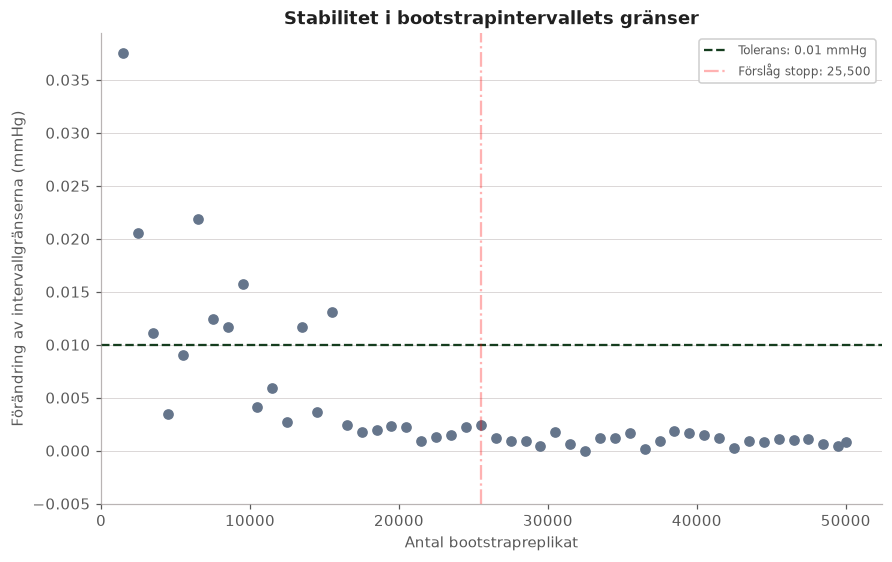

In [25]:
fig_bootstrap_stability, ax_bootstrap_stability = plt.subplots(
    figsize=(8, 5),
    layout="constrained"
)
plot_bootstrap_stability(
    ax_bootstrap_stability,
    bootstrap_check_sizes,
    bootstrap_ci_changes,
    stop_at,
    COLORS
)

plt.show()

Ändringarna i intervallgränserne bli nästan lika eller mindre när antalet replikation ökar. Met detta diagnostiska kriterium föreslår stoppa efter 25500 upprepningar.  
I diagram visas alla 50000 upprepningar och utvecklig bli efter rekomenderat stopp punkt.

### 6.4. Jämförelse mellan metoderna

In [26]:
ci_table = pd.DataFrame({
    "Metod": ["Normalapproximation", "Bootstrap"],
    "Nedre gräns (mmHG)": [normal_ci[0], bootstrap_ci[0]],
    "Över gräns (mmHg)":  [normal_ci[1], bootstrap_ci[1]]
})

display(ci_table.round(4).style.hide(axis="index"))

Metod,Nedre gräns (mmHG),Över gräns (mmHg)
Normalapproximation,148.292100,150.065100
Bootstrap,148.290500,150.069100


Båda metoderna ger nästan samma 95-procentiga konfidensintervall. Det är rimligt med ett relativt stort stickprov och en ungefär symmetrisk fördelning av blodtrycket. 

Normalapproximationen använder standardfelet och normalfördelningens kritiska värde, medan bootstrap använder percentiler från upprepade stickprov med återläggning.

Metoderna bygger dock på **samma dataset**. Att deras resultat liknar varandra är därför ingen oberoende bekräftelse på populationsmedelvärdet.  

## 7. Hypotesprövning

### Påstående :" Rökare har högre genomsnittligt systolisk blodtryck än icke-rökare."

### 7.1 Formulera hypoteser


H0: Rökare har inte högre medelblodtryck än icke-rökare.  
H1: Rökare har högre medelblodtryck än icke-rökare.  
  
Ett ensidigt t-test eftersom analysen vill undersöka om rökare har högre genomsnittligt systolisk blodtryck än icke-rökare, inte endast om grupperna skiljer sig åt. Riktningen anges i uppgiften.

Welchs t-test passar här därför att grupperna har olika antal personer, men just det är inte ensamt skäl att välja Welch. Andra skäl är att blotrycket behövs inte ha samma varians i båda grupperna, som krävs för students t-test.

### 7.2. Statistisk test - Welchs t-test
  
Signifikansnivå : Den acceptable risk att förkasta nollhypotesen trots att den är sannt(typ I-fel) valdes på höst 5 % . 

### 7.3 Data

In [27]:

(smoker_bp, no_smoker_bp,
smoker_n, non_smoker_n,
smoker_mean, non_smoker_mean,
smoker_std, non_smoker_std,
smoker_fraction,) = analyzer.smoking_analysis()

smoker_no_smoker_summary = pd.DataFrame({
    "Grupp": ["Rökare", "Icke-rökare"],
    "Antal": [smoker_n, non_smoker_n],
    "Medelblodtryck (mmHg)": [smoker_mean, non_smoker_mean],
    "Standardavvikelse": [smoker_std, non_smoker_std]
})

display(smoker_no_smoker_summary.round(4).style.hide(axis="index"))

Grupp,Antal,Medelblodtryck (mmHg),Standardavvikelse
Rökare,213,149.524900,13.267800
Icke-rökare,587,149.053000,12.626000


Det finn 213 rökare och 587 icke-rökare i datasetet. Skillnaden i genomsnittligt systolisk blodtryck  mellan rökare och icke-rökare är 0,47 mmHg. Rökare i daset har något högre medevärde, men det betyder inte att skillnaden bekräftar att rökning påverkat systolisk blodtryk.

### 7.4. Welch-testet


In [28]:
welch_ttest = analyzer.welch_test()

print(f"Welch t-statistik: {welch_ttest.statistic:.4f}")
print(f"Welch p-värde:     {welch_ttest.pvalue:.4f}")
print("\nReslutat: H0" , "förkastas." if welch_ttest.pvalue  < ALPHA  else "förkastas inte." )

Welch t-statistik: 0.4503
Welch p-värde:     0.3264

Reslutat: H0 förkastas inte.


Welchs ensidiga t-test ger p ≈ 0,3264, vilket är större än α = 0,05. **Nollhypotesen förkastas därför inte.**   
Analysen ger inte tillräckligt statistiskt stöd för att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.  


## 8. Power-analys genom simulering

Statistisk styrka (*power*) visar hur stor sannolikheten är att teste upptäcker en verklig skillnad mellan två grupper.
Här upprepas ett ensidigt Welch-test 10 000 gånger för varje urvalsstorlek. Andelen test med p < 0,05 ger en uppskattning av power.

**Viktig begränsning:** Den första simuleringen använder den **observerade** skillnaden på cirka 0,47 mmHg och de uppskattade standardavvikelserna. dessa värden antas vara sanna i modellen, men vi har ingen bevis om de motsvarar population. 

Urvalsstorlekarna 100–3 200 valdes för att visa utvecklingen under och över datasetets storlek (800 personer); 10 000 simuleringar ger en relativt stabil modellbaserad andel. Gruppandelen 213/800(rökare/alla) hålls konstant i denna första jämförelse.

In [29]:
power_results = analyzer.power_simulation(
    sample_sizes=POWER_SAMPLE_SIZE,
    n_power_sim=N_POWER_SIM,
    alpha=ALPHA,
    seed=RANDOM_SEED,
    batch_size=250,)

power_table = power_results.round(4).style.hide(axis="index")
display(power_table)

Total antal:,Simulation - antal rökare:,Simulation - antal icke-rökare:,Welch power:
100,27,73,0.067400
200,53,147,0.074800
400,106,294,0.092800
800,213,587,0.118500
1600,426,1174,0.151700
3200,852,2348,0.230500


Med 800 personer(storlek av datasetet) - 213 rökare a 587 icke-rökare är power cirka 11,85%. Det betyder att testet upptäcker observerande skillnaden(0,47mmHg) 12 gånger a 100.  

Tabbelen visar ocskå att power ökar när urvalsstorleken ökar från 100 till 3 200 personer i detta modellscenario.

## Del2

### 9. Syfte

Syftet med detaa del är att undersöka sambandet mellan systolickt blodtryck och olika hälsoretaterade variabler i datasetet.

Analysen inleds med en explorativ undersökning där sambanden visualiseras med spridningsdiagram och lådagram.
Enkelt och multipel linjär regression används för att analysera hur de olika variabler samvarierar med systoliskt blodtryck. Datasetet behandlas som tvärsnittsdata, samt antars att variablerna beskriver personens hälsotillstånd vid ungefär samma undersökningstillfälle. Datasetet innehåller dock ingen informationom exakta mättidpunkter och under vilka omstäldigheret(morgon/kväll, fastande/efter mat, i lugnt/efter ansträngningen) registrerades. Dessutom variabeln `disease` väljes att inte inkludera, eftersom datasetet saknar information om när sjukdomen uppstår i förhållande till blodtrycksmätningen. Detta gör det svårt att tolka sambandet och dess tidsmässiga riktning. 

Det betyder att snalysen fastställer inte orsaksamband. Analysen har fokus på statistiska sambans och mönster.

Slutligen används PCA för att undersöka om det finns övergripande mönster i datasets variabler.


### 9.1. Explorativ analys av samband

Syftet med den här avsnitt är att identifiera möjliga samband och mönster mellan systoliskt blodtryck och sex hälsorelaterade variabler, inför den fortsatta regressionsanalysen.

Numeriska variabler visualiseras med spridningsdiagram, där varje punkt motsvarar en person i datasetet.

Lådagram använs för `kön` och `rökstatus`, därför att det passar bättre för binär variabel.  

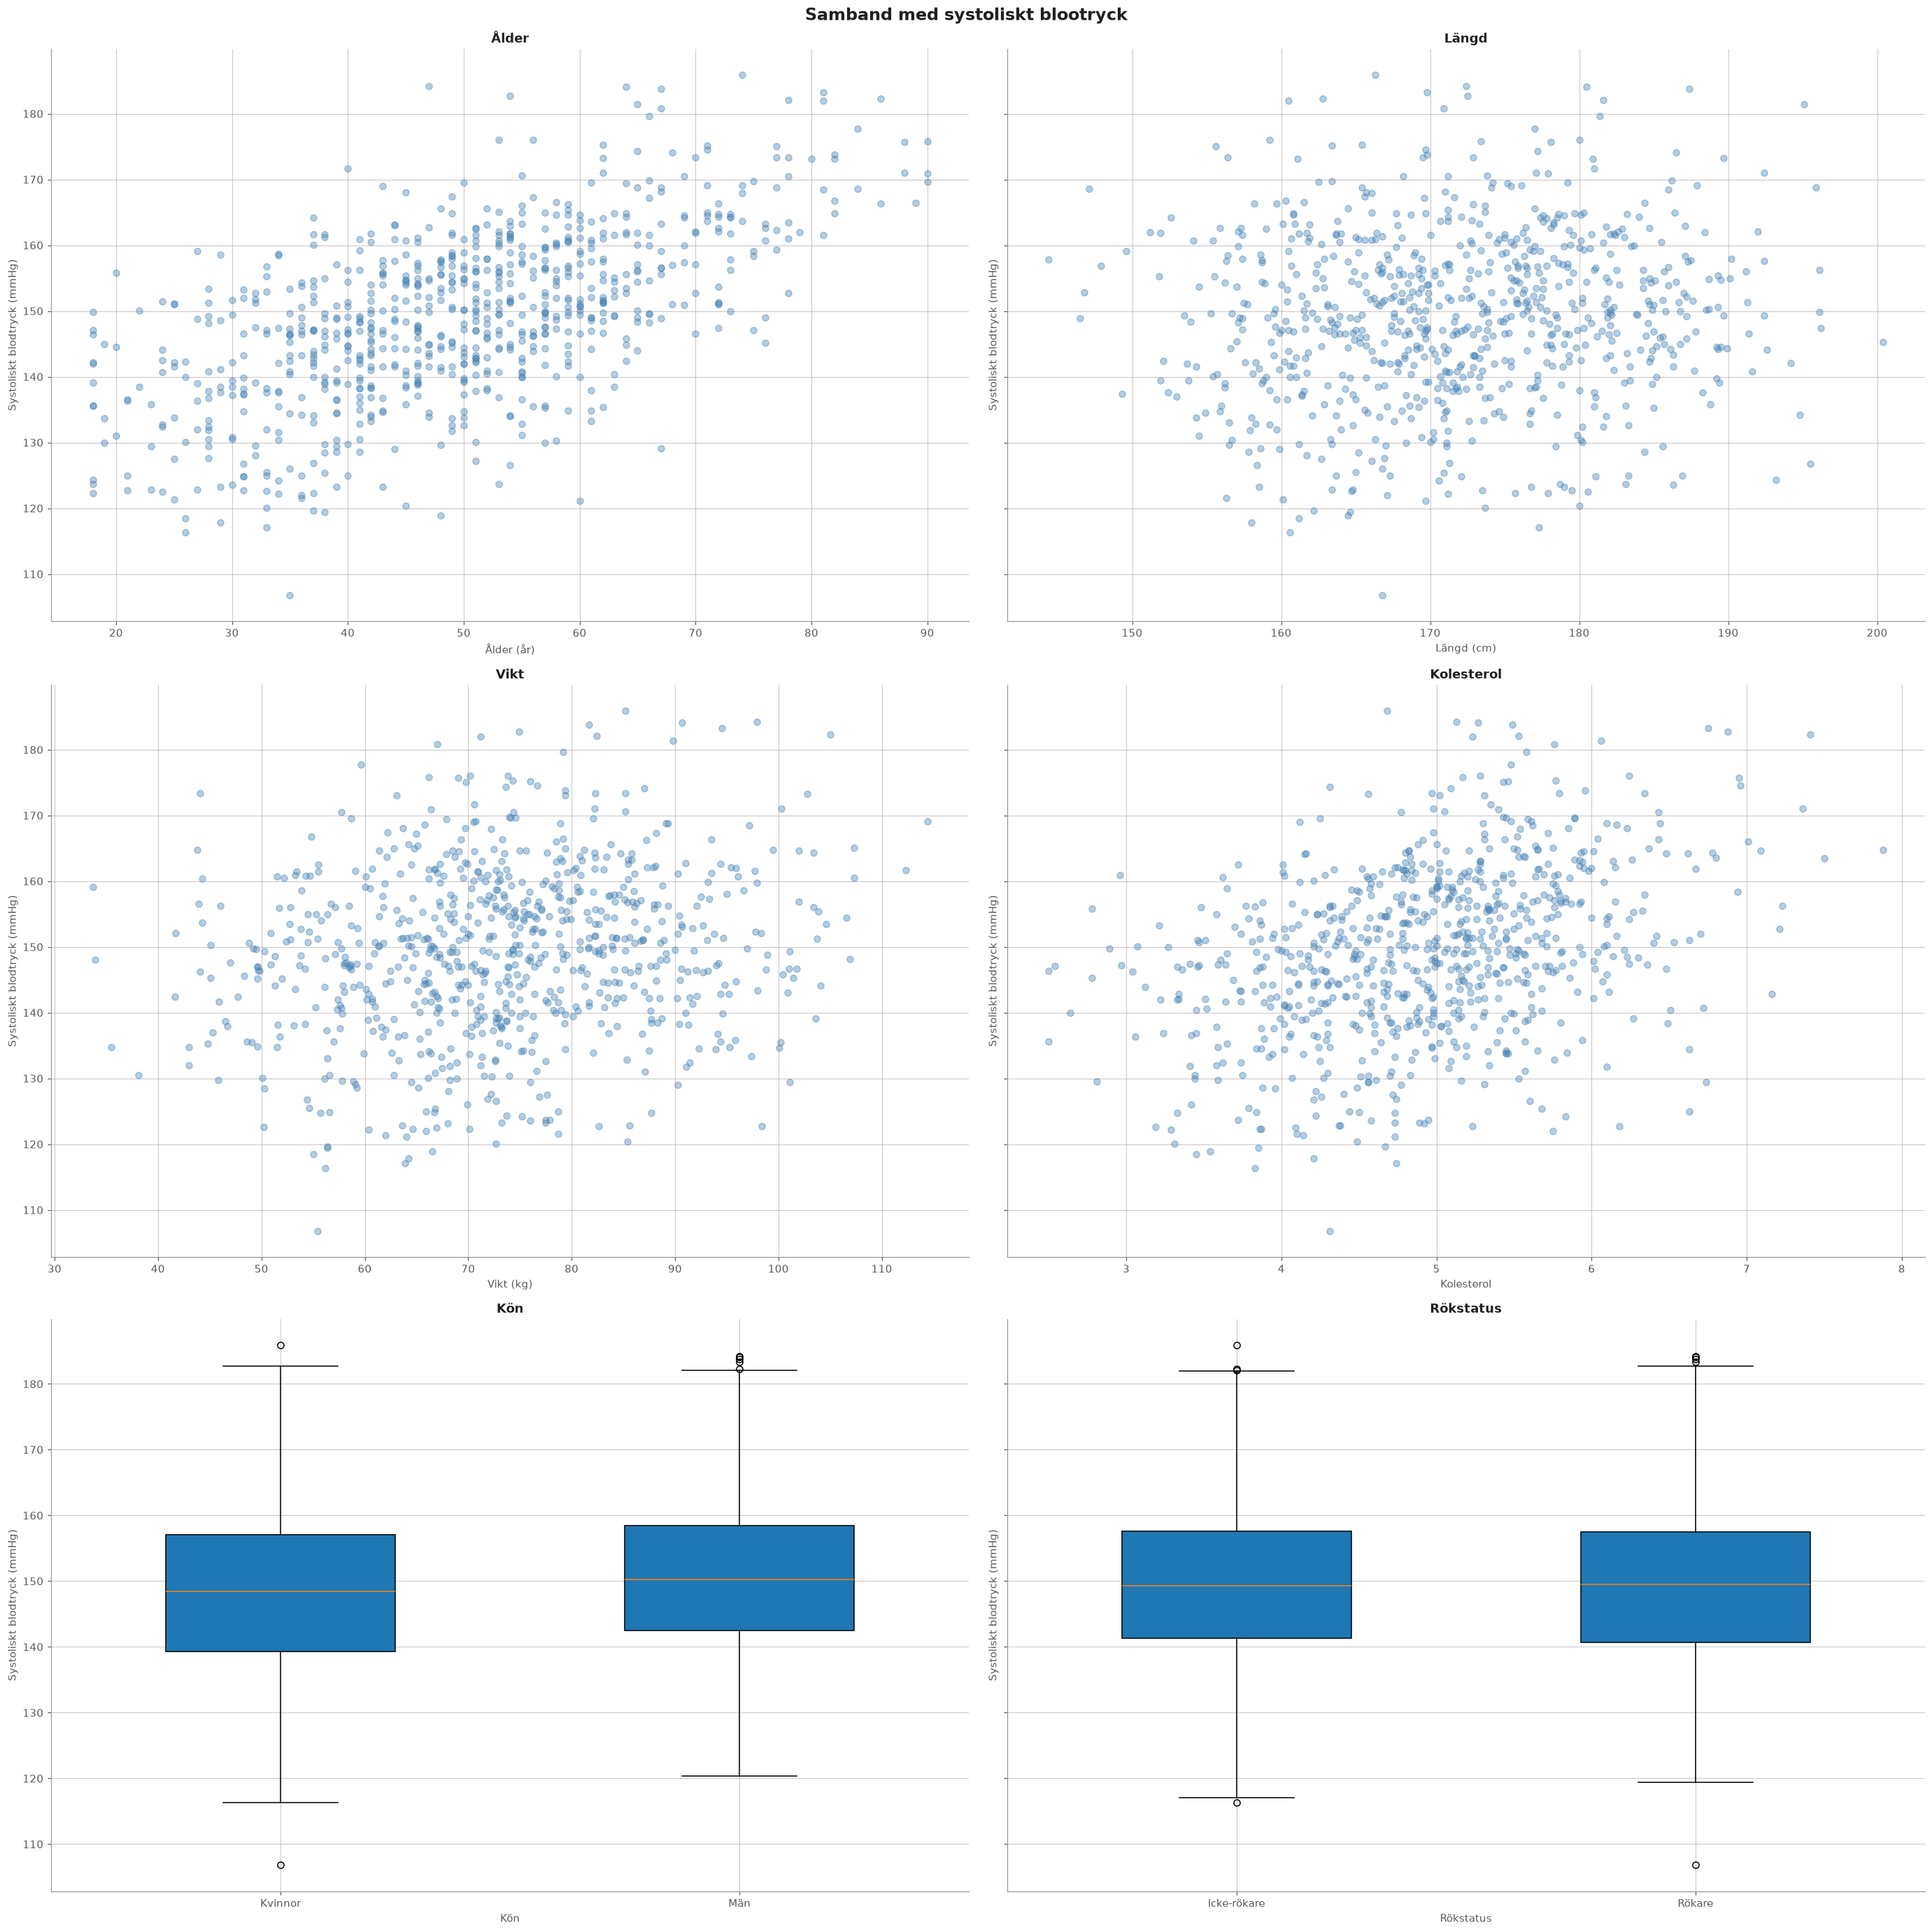

In [30]:
from src.viz import plot_bp_overview

fig, axes = plot_bp_overview(df)
plt.show()

I diagrammen:   
"Ålder" kan observeras positivt sambanden  - i datasetet har äldre personer högre blodtryck.  
"Längd" ingen tydligt linjärt samband observeras.  
"Vikt" kan observeras relativt stor spridning med svagt positivt samband.  
"Kolesterol" kan observeras positivt samband - i datasetet har personer med högre kolesterol högre blodtryck.  
"Kön" relativt lika fördelning, men något högre median för män. Dessutom flera avvikande värde utanför diagrammens whiskers observeras.   
"Rökstatus" relativt lika fördelning och flera avvikande värde utanför diagrammens whiskers observeras. 

### 9.2. Enkel linjär regression
Syftet är att uppskatta hur blodtrycket förändras med respektive variabel och hur stor andel av variationen i blodtrycket som varje model kan förklara.

Resultat används som utgångspunkt för den multipla regressionsanalysen.

In [31]:
columns = ["age", "height", "weight", "cholesterol", "sex", "smoker"]

regression_results = []

for column in columns: 
    model, X, y = analyzer.simple_regression(column)

    regression_results.append({
        "Variabel": column,
        "Koefficient": model.coef_[0],
        "Intercept": model.intercept_,
        "R^2": model.score(X, y),
        "Antal": len(y)
    })

simple_regression_table = pd.DataFrame(regression_results)

display(
    simple_regression_table.round(4).style.hide(axis="index")
)

Variabel,Koefficient,Intercept,R^2,Antal
age,0.536000,122.684900,0.369200,800
height,0.112600,129.827300,0.007400,800
weight,0.167800,136.861900,0.032200,800
cholesterol,5.555800,121.793300,0.135700,800
sex,2.113000,148.130000,0.006800,800
smoker,0.471900,149.053000,0.000300,800


Tabellen visar hur varje variabel för sig hänger ihop med systoliskt blodtryck. Koefficienten visar hur mycket blodtrycket i genomsnitt förändra när en variabel ökar med en enhet. R^2 visar hur stor del av variationen i blodtrycket som modellen kan förklara.
Den enkla linjära regressionen visar att ålder har det tydligaste enskilda linjära sambandet med systoliskt blodtryck. Modellen förklarar cirka 36,92 % av variationen i blodtrycket. Blodtryckt ökar i genomsnitt med 0,54 mmHg för varje extra år. Kolesterolvisar att när värdet ökar med en enhet ökar blodtrycket i genomsnitt med 5,56 mmHg, men modellen förklarar ungefär 14% av variationen. De andra variablerna förklarar betydligt mindre av variationen var för sig. 


### 9.3. Multipel linjär regression

I den här delen undersöks flera variabler samtidigt.

Syftet är att se hur varje variabel hänger ihop med systoliskt blodtryck när vi samtidigt tar hänsyn till de andra variablerna i modellen.

Modeller byggts stegvis:  
* Grundmodell : innehåller tre variebler - Ålder, Kolesterol, Vikt ....Ålder och Kolesterol visade de högsta förklaingsgraderna i den enkla regressionen. 
* Utökat modell : läggas till variebler - Kön och Rökstatus
* Fullständig modell : läggas till variabel - Längd 

Målet är att undersöka vilka variabler som bidrar med relevant information.

Justerad R2 ligger i högre fokus än R2, därför att justerad R2 tar hänsyn till antalet variabeler i modellen.

In [32]:
models ={
    "Grundmodell": ["age", "cholesterol", "weight"],
    "Utökad modell": ["age", "cholesterol", "weight", "sex", "smoker"],
    "Fullständig modell":  ["age", "cholesterol", "weight", "sex", "smoker", "height"],
}
model_results = []
for name, predictors in models.items():
    model_i, X_i, y_i = analyzer.multiple_regression(predictors)

    n = len(y_i)
    p= X_i.shape[1]
    r2 = model_i.score(X_i, y_i)
    adjusted_r2 = 1 - (1 - r2) * (n - 1)/(n-p - 1)

    model_results.append({
        "Modell": name,
        "Antal variabler": p,
        "R^2": r2,
        "Justerat R^2": adjusted_r2,
        "Antal": n
    })

model_comparison = pd.DataFrame(model_results)

display(model_comparison.round(4).style.hide(axis="index"))


Modell,Antal variabler,R^2,Justerat R^2,Antal
Grundmodell,3,0.405800,0.403600,800
Utökad modell,5,0.406300,0.402500,800
Fullständig modell,6,0.407100,0.402600,800


Tabellen visar att grundmodellen förklarar cirka 40,58% av variationnen i systoliskt blodtryck.  När fler variabler läggs till ökar R^2 väldig lite, samtidigt justerad R2 miskar. Detta är täcken på att irrelevanta variabels läggdes till. Med andra ord flera variabel har inte förbättrat modellens förklarningsgrad och därför grundmodellen föredras, trots att mer är halvan av variationen inte förklarars.

### 9.4. Jämförelse av regressionskoefficient

I den häe delen jämföras regressionskoefficienterna för att observera hur det förväntade blodtryck förändras näe en variabel ökar med en enhet.

,Grundmodell,Utökad modell,Fullständig modell
Imtercept,108.5107,108.8591,99.9632
age,0.5264,0.5266,0.5238
cholesterol,0.4315,0.4536,0.5298
weight,0.1706,0.1620,0.1604
sex,NaN,0.5037,-0.2057
smoker,NaN,-0.3280,-0.3068
height,NaN,NaN,0.0531


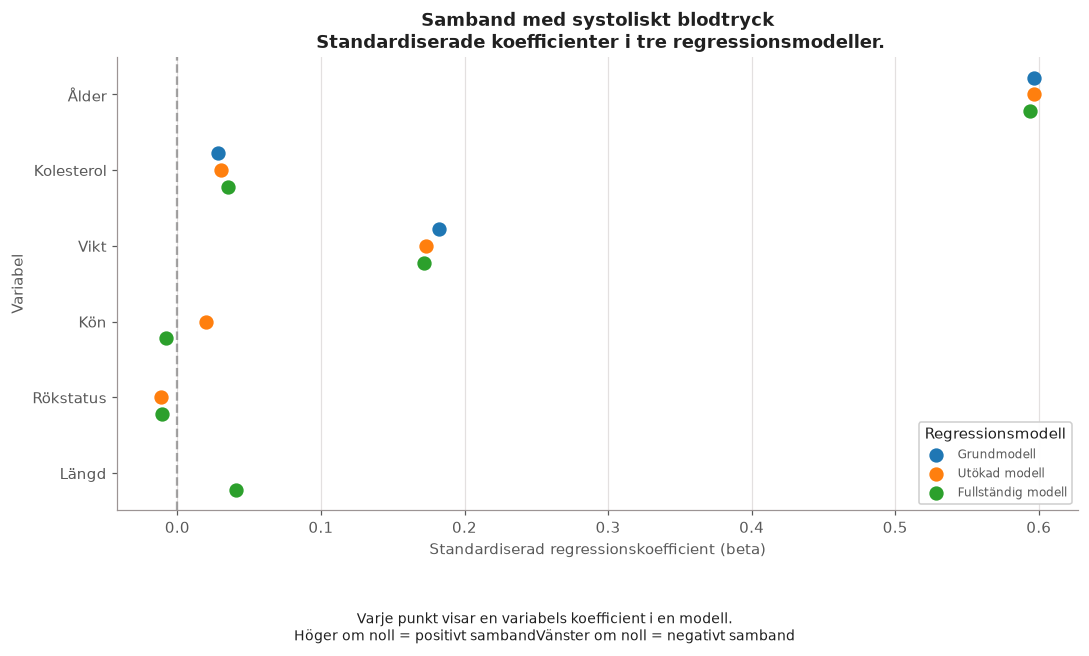

In [33]:
coefficients = {}
standardized_results = {}
for name, predictors in models.items():
    model_i, X_i, y_i = analyzer.multiple_regression(predictors)

    coefficients[name] = {"Imtercept": model_i.intercept_, **dict(zip(predictors, model_i.coef_))}
    beta = analyzer.standardized_coefficients(model_i, X_i, y_i)
    standardized_results[name] = dict(zip(predictors, beta))
    
standardized_table = pd.DataFrame(standardized_results)
    
fig, ax = src.viz.plot_standardized_coefficients(standardized_table)
    
    
coefficient_table = pd.DataFrame(coefficients)

display(coefficient_table.round(4))
plt.show()

In [34]:
evaluation_results = []

for name, predictors in models.items():
    results = analyzer.evaluate_regression(
        predictors,
        test_size=0.2,
        seed=42
    )

    evaluation_results.append({"Modell":name, **results})

evaluation_table = pd.DataFrame(evaluation_results)

display(evaluation_table.round(4).style.hide(axis="index"))

Modell,Train R^2,Test R^2,MAE,RMSE,Train antal,Test antal
Grundmodell,0.400400,0.422200,7.639200,9.750600,640,160
Utökad modell,0.400900,0.418300,7.654700,9.783100,640,160
Fullständig modell,0.403100,0.412400,7.724300,9.832800,640,160


### korsvalidering

In [35]:
cv_results = []

for name, predictors in models.items():
    scores = analyzer.regression_cross_validation(predictors, n_splits=5, seed=42)
    cv_results.append({"Modell": name, **scores})

cv_table = pd.DataFrame(cv_results)

display(cv_table.round(4).style.hide(axis="index"))

Modell,CV R^2,CV R^2 std,CV MAE,CV RMSE
Grundmodell,0.394100,0.046500,7.907800,9.894800
Utökad modell,0.391700,0.046800,7.924500,9.914100
Fullständig modell,0.390800,0.044900,7.938000,9.923600


## 10 PCA 

Målet är att undersöka vilka variabler 

In [36]:
pca_columns = ["age", "height", "weight", "cholesterol", "systolic_bp"]

pca_model, X_pca, pca_index = analyzer.pca_analysis(pca_columns)

print("Antal observationer:", len(pca_index))
print("Antal huvudkomponenter:", pca_model.n_components_)

Antal observationer: 800
Antal huvudkomponenter: 5


In [37]:
explained_variance = pd.DataFrame({ "Komponent": [f"PC{i+1}" for i in range(pca_model.n_components_)],
                                   "Förklarad varians (%)": pca_model.explained_variance_ratio_ * 100, 
                                   "Kumulativ varians (%)": pca_model.explained_variance_ratio_.cumsum() * 100})

display(explained_variance.round(2).style.hide(axis="index"))

Komponent,Förklarad varians (%),Kumulativ varians (%)
PC1,40.910000,40.910000
PC2,26.040000,66.960000
PC3,16.040000,83.000000
PC4,10.820000,93.830000
PC5,6.170000,100.000000


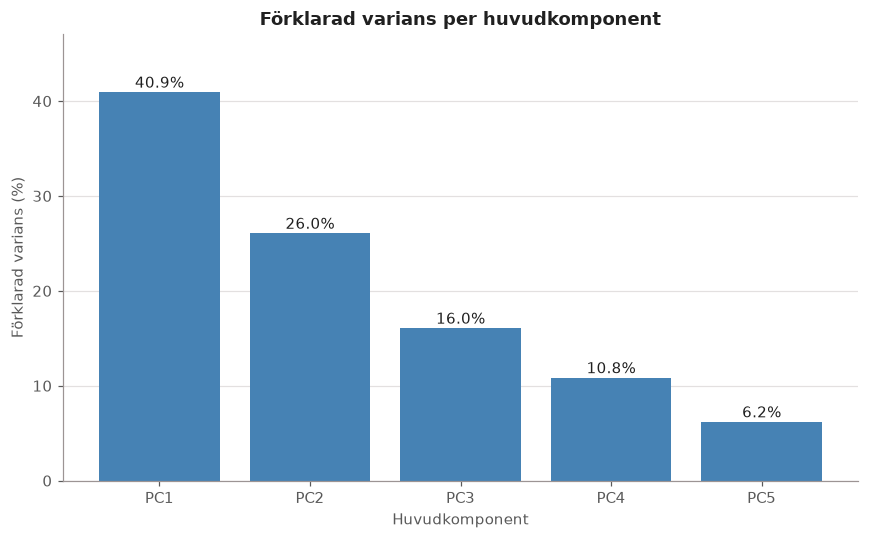

In [38]:
from src.viz import plot_pca_variance
fig, ax = plot_pca_variance(pca_model)
plt.show()

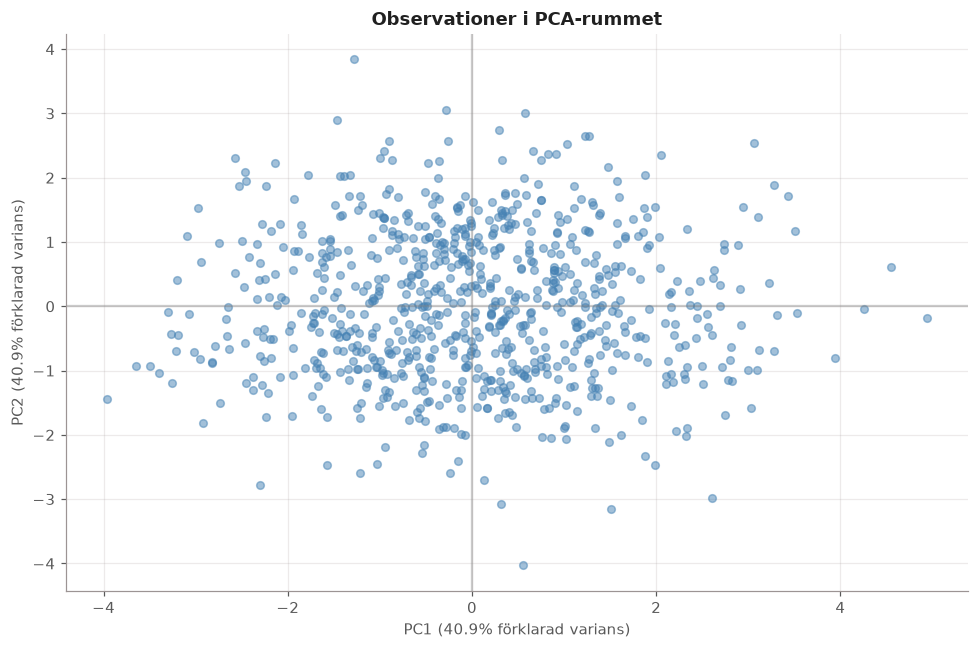

In [39]:
from src.viz import  plot_pca_scores

fig, ax = plot_pca_scores(X_pca, pca_model)

plt.show()

In [40]:
pca_loadings = pd.DataFrame(pca_model.components_.T, index=pca_columns, columns=[f"PC{i + 1}" for i in range(pca_model.n_components_)])
display(pca_loadings[["PC1", "PC2"]].round(4))

,PC1,PC2
age,0.5732,-0.2800
height,0.0983,0.6938
weight,0.2472,0.6572
cholesterol,0.5262,-0.0694
systolic_bp,0.5690,-0.0591


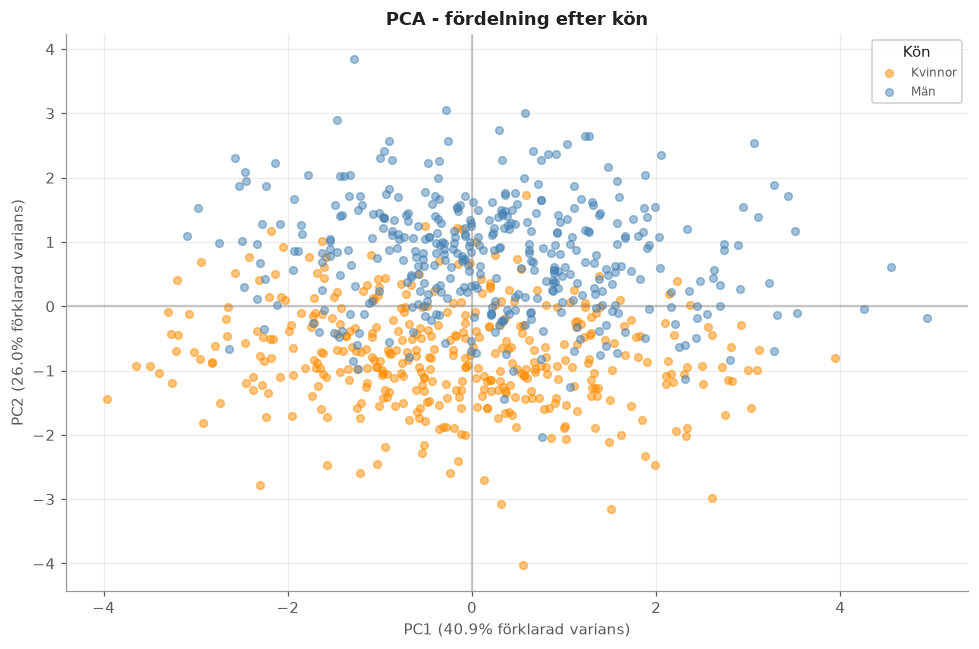

In [41]:
from src.viz import plot_pca_by_sex

sex = df.loc[pca_index, "sex"].to_numpy()

fig, ax = plot_pca_by_sex(X_pca, pca_model, sex)

plt.show()

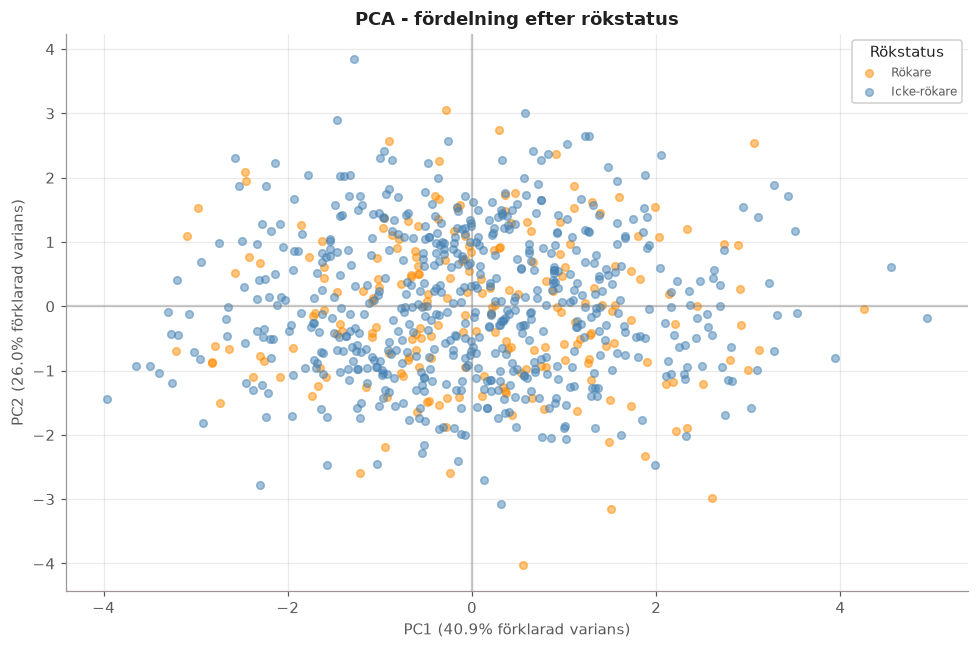

In [43]:
from src.viz import plot_pca_by_smoker

smoker = df.loc[pca_index, "smoker"].to_numpy()

fig, ax = plot_pca_by_smoker(X_pca, pca_model, smoker)

plt.show()

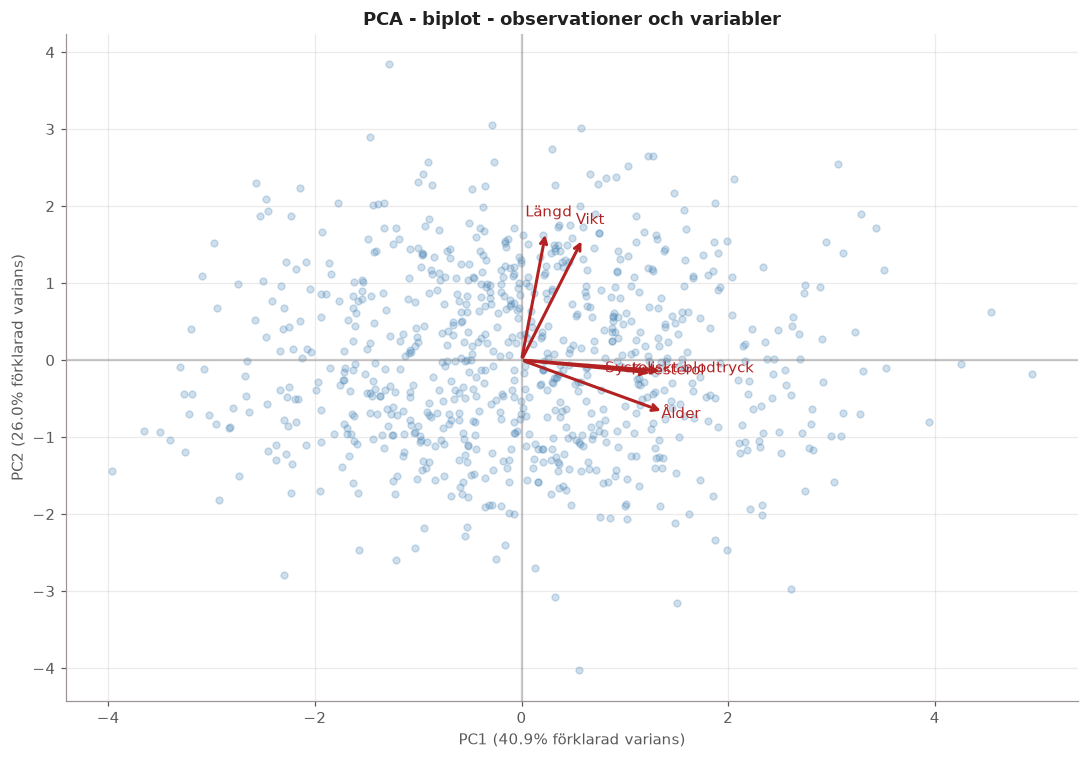

In [ ]:
from src.viz import plot_pca_biplot
fig, ax = plot_pca_biplot(
    X_pca, pca_model, pca_columns
)
plt.show()